In [3]:
import os
print(os.listdir())

['.ipynb_checkpoints', 'churn-bigml-20.csv', 'churn-bigml-80.csv', 'Churn_Prediction.ipynb', 'cleaned_iris.csv', 'house_prediction.csv', 'House_Regression.ipynb', 'Iris Dataset.ipynb', 'iris.csv']


In [3]:
import pandas as pd

train_df = pd.read_csv("churn-bigml-80.csv")
test_df = pd.read_csv("churn-bigml-20.csv")

In [5]:
train_df.shape, test_df.shape

((2666, 20), (667, 20))

In [6]:
train_df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [7]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   object 
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   object 
 4   Voice mail plan         2666 non-null   object 
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   

In [8]:
train_df.isnull().sum()

State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes       0
Total night calls         0
Total night charge        0
Total intl minutes        0
Total intl calls          0
Total intl charge         0
Customer service calls    0
Churn                     0
dtype: int64

In [9]:
train_df.duplicated().sum()

np.int64(0)

In [10]:
train_df['Churn'].value_counts()

Churn
False    2278
True      388
Name: count, dtype: int64

In [11]:
train_df['Churn'].value_counts(normalize=True)*100

Churn
False    85.446362
True     14.553638
Name: proportion, dtype: float64

In [12]:
train_df['International plan'] = train_df['International plan'].map({'No':0,'Yes':1})
train_df['Voice mail plan'] = train_df['Voice mail plan'].map({'No':0,'Yes':1})

test_df['International plan'] = test_df['International plan'].map({'No':0,'Yes':1})
test_df['Voice mail plan'] = test_df['Voice mail plan'].map({'No':0,'Yes':1})

In [13]:
train_df = train_df.drop('State', axis=1)
test_df = test_df.drop('State', axis=1)

In [14]:
train_df.head()

,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,128,415,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,107,415,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,137,415,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,84,408,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,75,415,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [15]:
X_train = train_df.drop('Churn', axis=1)
y_train = train_df['Churn']

X_test = test_df.drop('Churn', axis=1)
y_test = test_df['Churn']

In [16]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

print("Model Trained Successfully")

Model Trained Successfully


In [20]:
DecisionTreeClassifier(random_state=42)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [17]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[False False  True False False False False False False False]


In [18]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9130434782608695


In [4]:
train_df.head()

,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [5]:
print("Training Dataset Shape:", train_df.shape)
print("Testing Dataset Shape:", test_df.shape)

Training Dataset Shape: (2666, 20)
Testing Dataset Shape: (667, 20)


In [6]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2666 entries, 0 to 2665
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   State                   2666 non-null   object 
 1   Account length          2666 non-null   int64  
 2   Area code               2666 non-null   int64  
 3   International plan      2666 non-null   object 
 4   Voice mail plan         2666 non-null   object 
 5   Number vmail messages   2666 non-null   int64  
 6   Total day minutes       2666 non-null   float64
 7   Total day calls         2666 non-null   int64  
 8   Total day charge        2666 non-null   float64
 9   Total eve minutes       2666 non-null   float64
 10  Total eve calls         2666 non-null   int64  
 11  Total eve charge        2666 non-null   float64
 12  Total night minutes     2666 non-null   float64
 13  Total night calls       2666 non-null   int64  
 14  Total night charge      2666 non-null   

In [7]:
print("Missing Values in Training Dataset:")
print(train_df.isnull().sum())

Missing Values in Training Dataset:
State                     0
Account length            0
Area code                 0
International plan        0
Voice mail plan           0
Number vmail messages     0
Total day minutes         0
Total day calls           0
Total day charge          0
Total eve minutes         0
Total eve calls           0
Total eve charge          0
Total night minutes       0
Total night calls         0
Total night charge        0
Total intl minutes        0
Total intl calls          0
Total intl charge         0
Customer service calls    0
Churn                     0
dtype: int64


In [8]:
print("Duplicate Records:", train_df.duplicated().sum())

Duplicate Records: 0


In [9]:
train_df.describe()

,Account length,Area code,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls
count,2666.000000,2666.000000,2666.000000,2666.00000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000,2666.000000
mean,100.620405,437.438860,8.021755,179.48162,100.310203,30.512404,200.386159,100.023631,17.033072,201.168942,100.106152,9.052689,10.237022,4.467367,2.764490,1.562641
std,39.563974,42.521018,13.612277,54.21035,19.988162,9.215733,50.951515,20.161445,4.330864,50.780323,19.418459,2.285120,2.788349,2.456195,0.752812,1.311236
min,1.000000,408.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,43.700000,33.000000,1.970000,0.000000,0.000000,0.000000,0.000000
25%,73.000000,408.000000,0.000000,143.40000,87.000000,24.380000,165.300000,87.000000,14.050000,166.925000,87.000000,7.512500,8.500000,3.000000,2.300000,1.000000
50%,100.000000,415.000000,0.000000,179.95000,101.000000,30.590000,200.900000,100.000000,17.080000,201.150000,100.000000,9.050000,10.200000,4.000000,2.750000,1.000000
75%,127.000000,510.000000,19.000000,215.90000,114.000000,36.700000,235.100000,114.000000,19.980000,236.475000,113.000000,10.640000,12.100000,6.000000,3.270000,2.000000
max,243.000000,510.000000,50.000000,350.80000,160.000000,59.640000,363.700000,170.000000,30.910000,395.000000,166.000000,17.770000,20.000000,20.000000,5.400000,9.000000


In [10]:
print(train_df['Churn'].value_counts())

Churn
False    2278
True      388
Name: count, dtype: int64


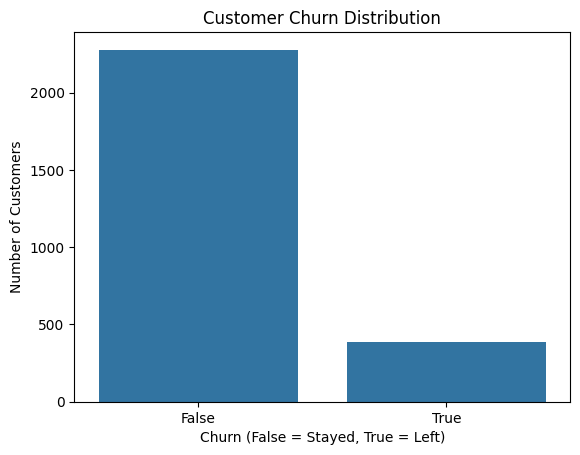

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='Churn', data=train_df)
plt.title('Customer Churn Distribution')
plt.xlabel('Churn (False = Stayed, True = Left)')
plt.ylabel('Number of Customers')
plt.show()

In [12]:
churn_percentage = train_df['Churn'].value_counts(normalize=True) * 100

print("Churn Percentage:")
print(churn_percentage)

Churn Percentage:
Churn
False    85.446362
True     14.553638
Name: proportion, dtype: float64


In [13]:
pd.crosstab(
    train_df['International plan'],
    train_df['Churn'],
    normalize='index'
) * 100

Churn,False,True
International plan,,
No,88.731219,11.268781
Yes,56.296296,43.703704


In [14]:
pd.crosstab(
    train_df['Voice mail plan'],
    train_df['Churn'],
    normalize='index'
) * 100

Churn,False,True
Voice mail plan,,
No,83.290222,16.709778
Yes,91.132333,8.867667


In [15]:
pd.crosstab(
    train_df['Customer service calls'],
    train_df['Churn'],
    normalize='index'
) * 100

Churn,False,True
Customer service calls,,
0,85.765766,14.234234
1,89.523810,10.476190
2,89.802632,10.197368
3,89.367816,10.632184
4,51.879699,48.120301
5,40.816327,59.183673
6,41.176471,58.823529
7,37.500000,62.500000
8,0.000000,100.000000


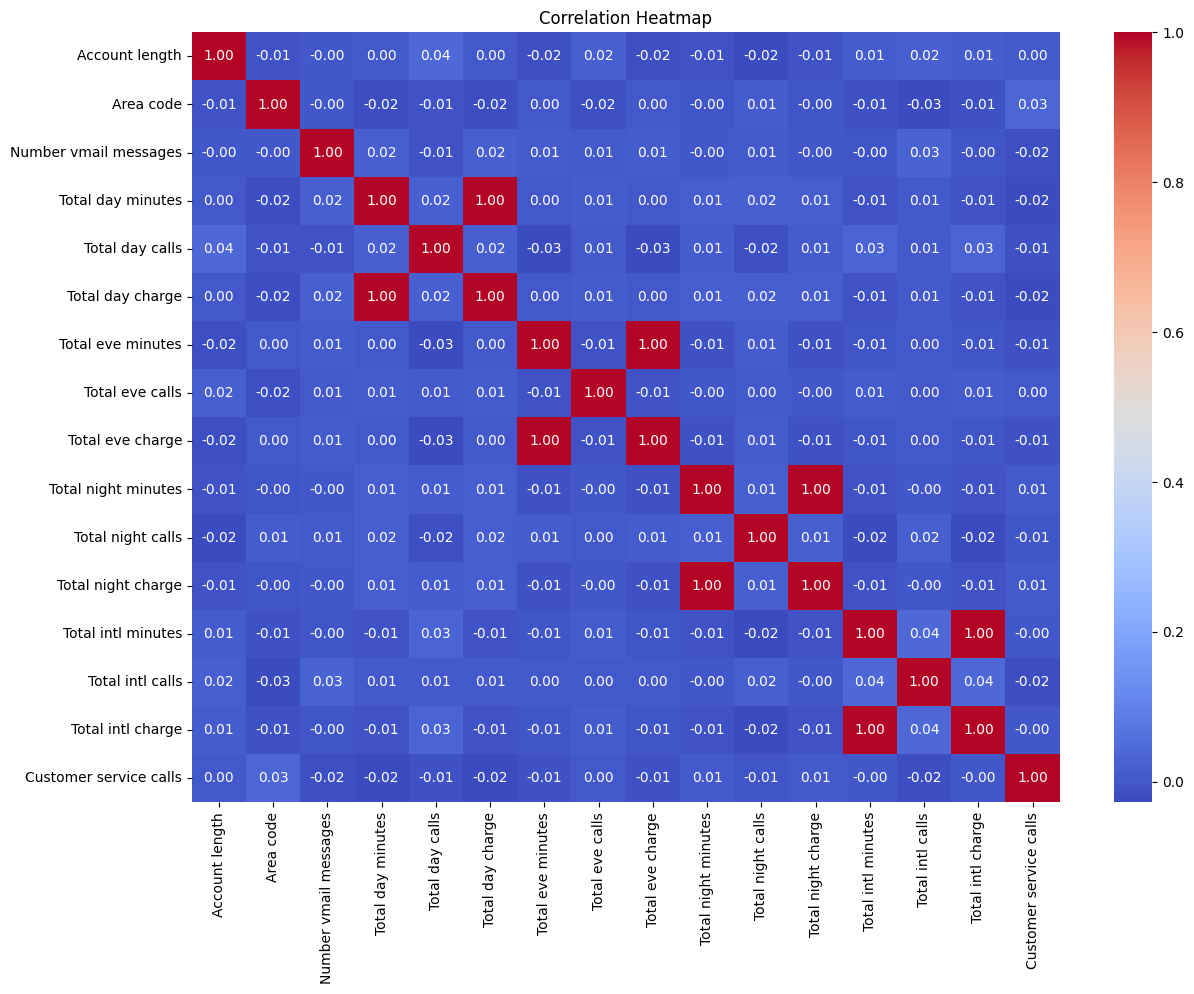

In [16]:
plt.figure(figsize=(14, 10))

numeric_df = train_df.select_dtypes(include=['number'])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

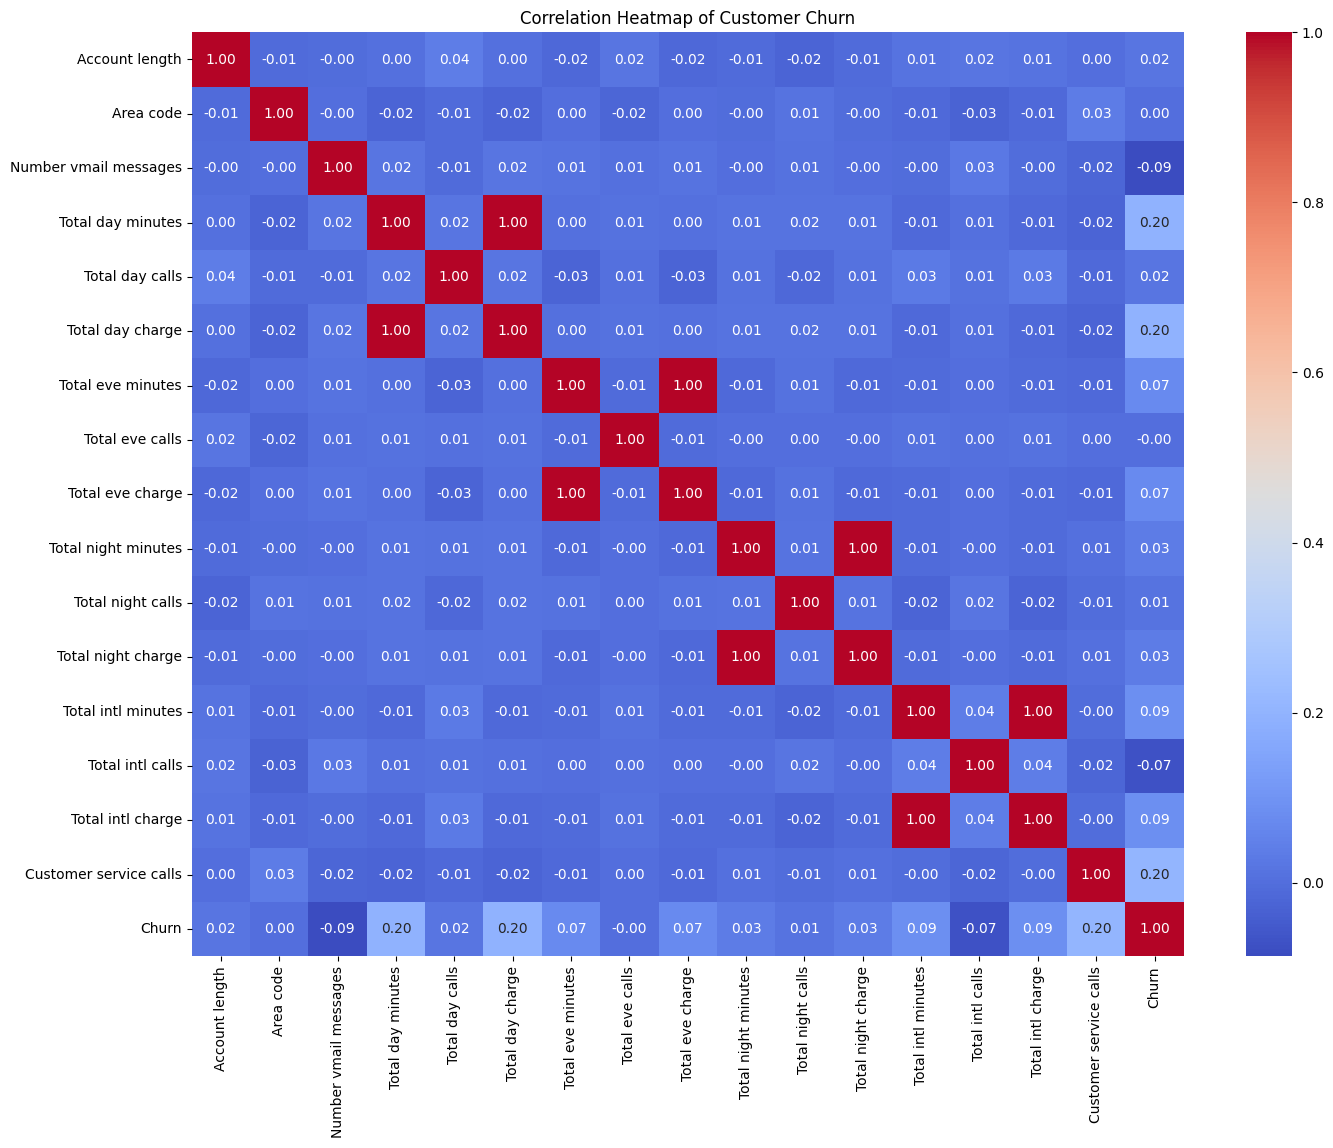

In [17]:
plt.figure(figsize=(16, 12))

corr_df = train_df.copy()
corr_df['Churn'] = corr_df['Churn'].astype(int)

numeric_df = corr_df.select_dtypes(include=['number'])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Customer Churn')
plt.show()

In [18]:
# Convert categorical columns into numerical format

train_encoded = pd.get_dummies(train_df, drop_first=True)
test_encoded = pd.get_dummies(test_df, drop_first=True)

# Align training and testing columns
test_encoded = test_encoded.reindex(
    columns=train_encoded.columns,
    fill_value=0
)

print("Training Data Shape:", train_encoded.shape)
print("Testing Data Shape:", test_encoded.shape)

Training Data Shape: (2666, 69)
Testing Data Shape: (667, 69)


In [19]:
# Separate features and target variable

X_train = train_encoded.drop('Churn', axis=1)
y_train = train_encoded['Churn']

X_test = test_encoded.drop('Churn', axis=1)
y_test = test_encoded['Churn']

print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)
print("X_test Shape:", X_test.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (2666, 68)
y_train Shape: (2666,)
X_test Shape: (667, 68)
y_test Shape: (667,)


In [20]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest Model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

# Train the model
model.fit(X_train, y_train)

print("Random Forest Model Training Completed Successfully!")

Random Forest Model Training Completed Successfully!


In [21]:
# Predict Customer Churn
y_pred = model.predict(X_test)

print("Predictions Completed Successfully!")
print("First 10 Predictions:", y_pred[:10])

Predictions Completed Successfully!
First 10 Predictions: [False  True  True False False False False False False False]


In [22]:
from sklearn.metrics import accuracy_score, classification_report

# Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 94.15 %

Classification Report:
              precision    recall  f1-score   support

       False       0.94      1.00      0.97       572
        True       1.00      0.59      0.74        95

    accuracy                           0.94       667
   macro avg       0.97      0.79      0.85       667
weighted avg       0.95      0.94      0.93       667



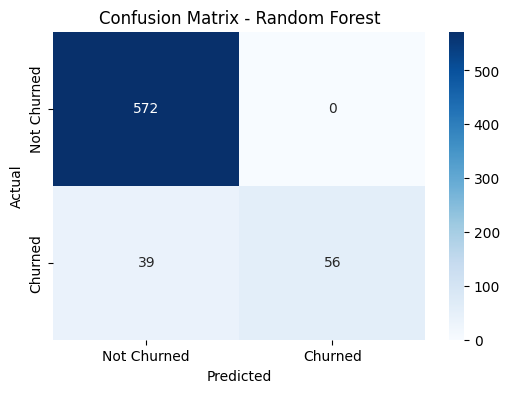

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churned', 'Churned'],
    yticklabels=['Not Churned', 'Churned']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Random Forest')
plt.show()

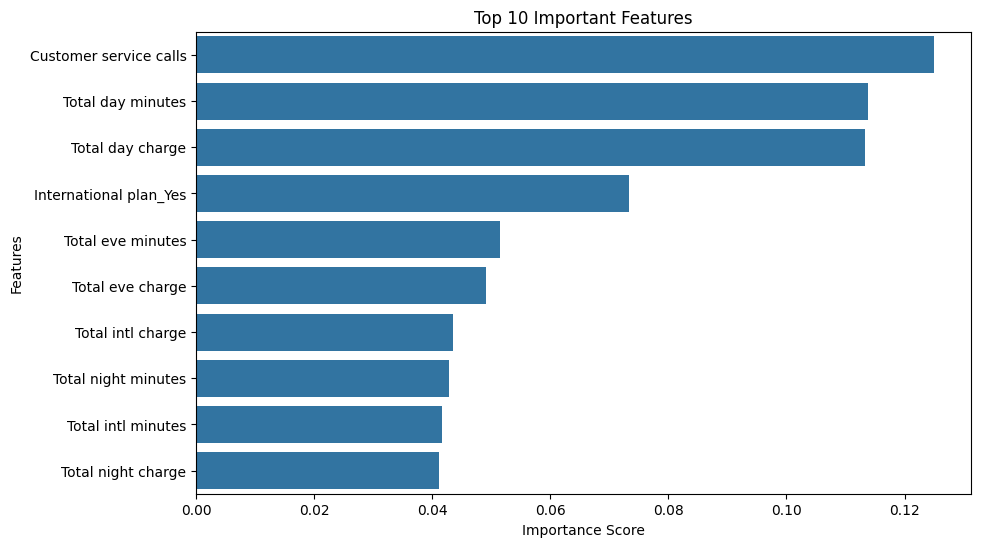

In [24]:
# Feature Importance

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance.head(10)
)

plt.title('Top 10 Important Features')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

In [25]:
import joblib

# Save trained model and feature names
model_data = {
    'model': model,
    'features': X_train.columns.tolist()
}

joblib.dump(model_data, 'customer_churn_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [27]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Create Logistic Regression Pipeline
log_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

# Train the model
log_model.fit(X_train, y_train)

print("Logistic Regression Model Training Completed!")

Logistic Regression Model Training Completed!


In [28]:
# Predict using Logistic Regression
y_pred_log = log_model.predict(X_test)

print("Logistic Regression Predictions Completed!")
print("First 10 Predictions:", y_pred_log[:10])

Logistic Regression Predictions Completed!
First 10 Predictions: [False  True  True False False False  True  True False False]


In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate Random Forest Metrics
rf_results = {
    'Model': 'Random Forest',
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1 Score': f1_score(y_test, y_pred)
}

# Calculate Logistic Regression Metrics
log_results = {
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test, y_pred_log),
    'Precision': precision_score(y_test, y_pred_log),
    'Recall': recall_score(y_test, y_pred_log),
    'F1 Score': f1_score(y_test, y_pred_log)
}

# Comparison Table
comparison_df = pd.DataFrame([rf_results, log_results])

print("Model Performance Comparison")
display(comparison_df.round(3))

Model Performance Comparison


,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.942,1.000,0.589,0.742
1,Logistic Regression,0.778,0.365,0.758,0.493


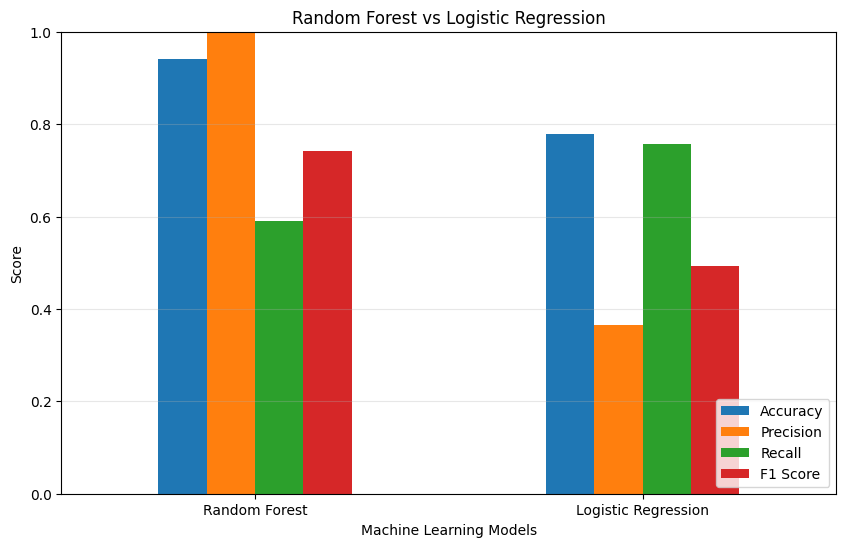

In [31]:
# Compare Model Performance Visually

comparison_plot = comparison_df.set_index('Model')

comparison_plot.plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title('Random Forest vs Logistic Regression')
plt.ylabel('Score')
plt.xlabel('Machine Learning Models')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()

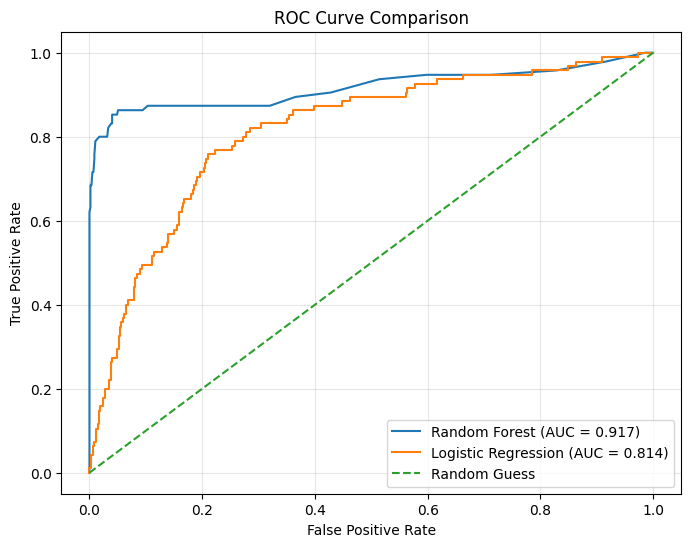

Random Forest AUC: 0.917
Logistic Regression AUC: 0.814


In [32]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC values
rf_prob = model.predict_proba(X_test)[:, 1]
log_prob = log_model.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, rf_prob)
log_auc = roc_auc_score(y_test, log_prob)

# Plot ROC Curve
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
log_fpr, log_tpr, _ = roc_curve(y_test, log_prob)

plt.figure(figsize=(8, 6))

plt.plot(rf_fpr, rf_tpr, label=f'Random Forest (AUC = {rf_auc:.3f})')
plt.plot(log_fpr, log_tpr, label=f'Logistic Regression (AUC = {log_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Random Forest AUC:", round(rf_auc, 3))
print("Logistic Regression AUC:", round(log_auc, 3))

In [34]:
# Improve Recall using Classification Threshold

rf_prob = model.predict_proba(X_test)[:, 1]

# Set a lower threshold
y_pred_adjusted = (rf_prob >= 0.30)

from sklearn.metrics import classification_report

print("Classification Report After Threshold Adjustment:")
print(classification_report(y_test, y_pred_adjusted))

Classification Report After Threshold Adjustment:
              precision    recall  f1-score   support

       False       0.97      0.96      0.97       572
        True       0.77      0.83      0.80        95

    accuracy                           0.94       667
   macro avg       0.87      0.90      0.88       667
weighted avg       0.94      0.94      0.94       667



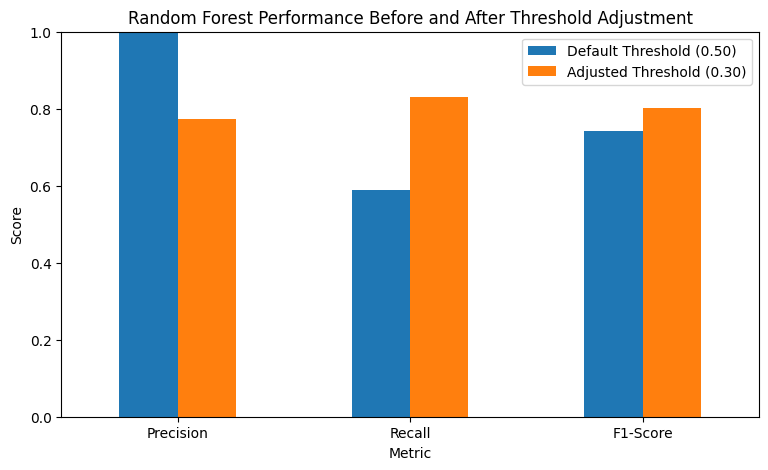

,Metric,Default Threshold (0.50),Adjusted Threshold (0.30)
0,Precision,1.000,0.775
1,Recall,0.589,0.832
2,F1-Score,0.742,0.802


In [37]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_comparison = pd.DataFrame({
    'Metric': ['Precision', 'Recall', 'F1-Score'],
    'Default Threshold (0.50)': [
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred)
    ],
    'Adjusted Threshold (0.30)': [
        precision_score(y_test, y_pred_adjusted),
        recall_score(y_test, y_pred_adjusted),
        f1_score(y_test, y_pred_adjusted)
    ]
})

threshold_comparison.set_index('Metric').plot(
    kind='bar',
    figsize=(9, 5),
    ylim=(0, 1),
    rot=0
)

plt.title('Random Forest Performance Before and After Threshold Adjustment')
plt.ylabel('Score')
plt.show()

display(threshold_comparison.round(3))

In [38]:
import joblib

saved_model = joblib.load('customer_churn_final_model.pkl')

print("Model loaded successfully!")
print("Model Type:", type(saved_model['model']))
print("Threshold:", saved_model['threshold'])

Model loaded successfully!
Model Type: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Threshold: 0.3


In [39]:
import os

print(os.path.exists('customer_churn_final_model.pkl'))

True


In [40]:
import joblib

saved_model = joblib.load('customer_churn_final_model.pkl')

print("Model loaded successfully!")
print("Model:", type(saved_model['model']))
print("Threshold:", saved_model['threshold'])

Model loaded successfully!
Model: <class 'sklearn.ensemble._forest.RandomForestClassifier'>
Threshold: 0.3


In [36]:
import joblib

final_model_data = {
    'model': model,
    'features': X_train.columns.tolist(),
    'threshold': 0.30
}

joblib.dump(
    final_model_data,
    'customer_churn_final_model.pkl'
)

print("Final Improved Model Saved Successfully!")

Final Improved Model Saved Successfully!


In [41]:
import pandas as pd

train_df = pd.read_csv("churn-bigml-80.csv")
test_df = pd.read_csv("churn-bigml-20.csv")

print("Training Dataset:", train_df.shape)
print("Testing Dataset:", test_df.shape)

Training Dataset: (2666, 20)
Testing Dataset: (667, 20)


## Final Results and Conclusion

### Project Results

- Dataset: Telecom Customer Churn Dataset
- Training Records: 2666
- Testing Records: 667
- Machine Learning Algorithms: Random Forest and Logistic Regression
- Random Forest Accuracy: 94.15%
- Logistic Regression Accuracy: 77.8%
- Random Forest AUC Score: 0.917
- Logistic Regression AUC Score: 0.814
- Improved Churn Recall: 83.2%
- Improved F1-Score: 80.2%
- Final Model: Random Forest Classifier
- Classification Threshold: 0.30

### Conclusion

This project focuses on predicting customer churn using Machine Learning techniques. Data cleaning, exploratory data analysis, data visualization and model building were performed using Python.

Random Forest and Logistic Regression algorithms were compared. Random Forest achieved better overall performance. By adjusting the classification threshold to 0.30, the churn recall improved from 58.9% to 83.2%.

This project demonstrates how Machine Learning can help telecom companies identify customers who may leave their services and develop better customer retention strategies.